In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("figures", exist_ok=True)
df = pd.read_parquet("data_clean/train_clean_v2.parquet")
df["hour"] = df.pickup_datetime.dt.hour
df["dow"] = df.pickup_datetime.dt.dayofweek       # 0 = Monday

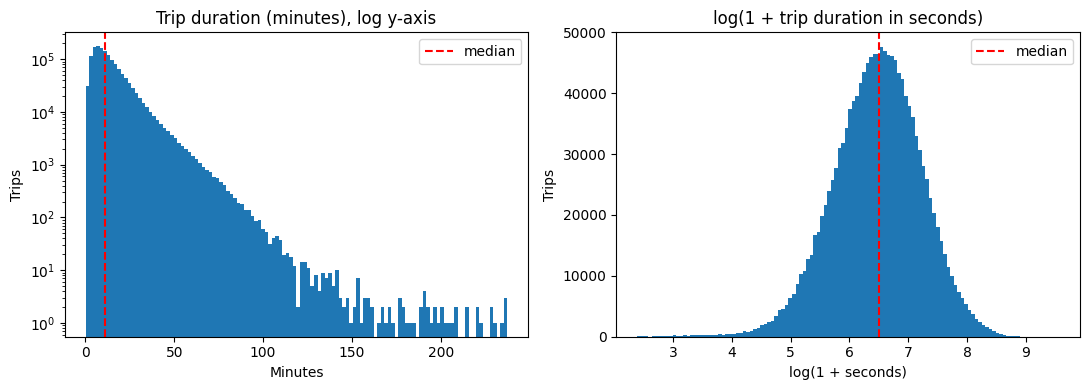

In [2]:
# Fig 1: duration distribution, raw vs log
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# Left: raw duration in minutes, log y-axis
ax[0].hist(df.trip_duration / 60, bins=120)
ax[0].set_yscale("log")
ax[0].axvline(df.trip_duration.median() / 60, color="red", ls="--", label="median")
ax[0].set_title("Trip duration (minutes), log y-axis")
ax[0].set_xlabel("Minutes"); ax[0].set_ylabel("Trips")
ax[0].legend()

# Right: log-transformed duration
ax[1].hist(np.log1p(df.trip_duration), bins=120)
ax[1].axvline(np.log1p(df.trip_duration.median()), color="red", ls="--", label="median")
ax[1].set_title("log(1 + trip duration in seconds)")
ax[1].set_xlabel("log(1 + seconds)"); ax[1].set_ylabel("Trips")
ax[1].legend()

plt.tight_layout()
plt.savefig("figures/fig1_duration_dist.png", dpi=200, bbox_inches="tight")
plt.show()

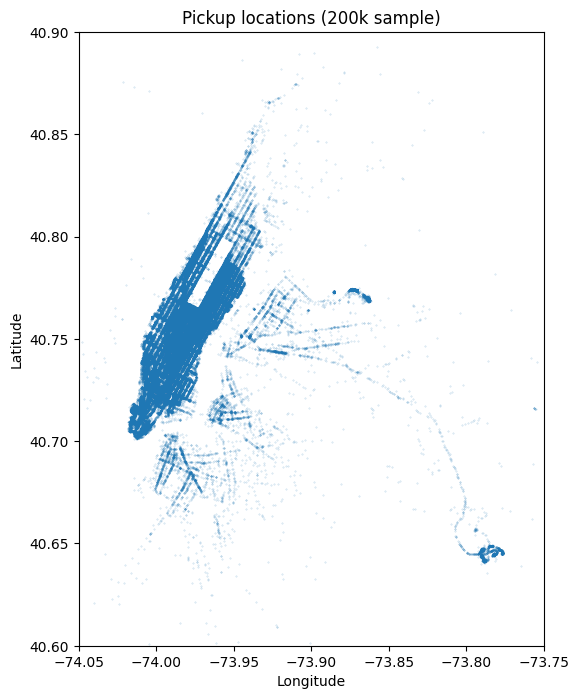

In [3]:
# Fig 2: pickup locations
s = df.sample(200000, random_state=42)
plt.figure(figsize=(6, 8))
plt.scatter(s.pickup_longitude, s.pickup_latitude, s=0.1, alpha=0.3)
plt.gca().set_aspect(1 / np.cos(np.deg2rad(40.75)))
plt.xlim(-74.05, -73.75); plt.ylim(40.6, 40.9)
plt.title("Pickup locations (200k sample)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.savefig("figures/fig2_pickup_map.png", dpi=200, bbox_inches="tight")

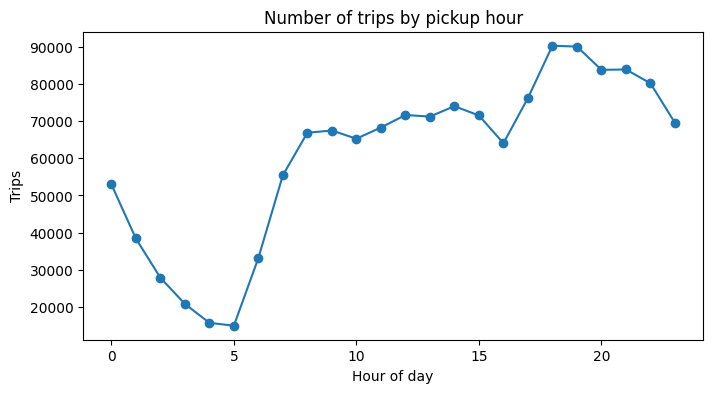

In [4]:
# Fig 3: trips per hour
plt.figure(figsize=(8, 4))
df.groupby("hour").size().plot(marker="o")
plt.title("Number of trips by pickup hour")
plt.xlabel("Hour of day"); plt.ylabel("Trips")
plt.savefig("figures/fig3_trips_by_hour.png", dpi=200, bbox_inches="tight")

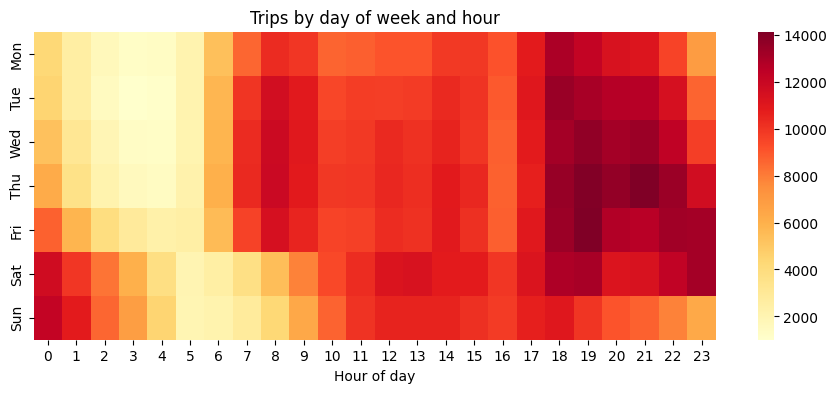

In [5]:
# Fig 4: day-of-week x hour heatmap
pt = df.pivot_table(index="dow", columns="hour", values="id", aggfunc="count")
pt.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.figure(figsize=(11, 4))
sns.heatmap(pt, cmap="YlOrRd")
plt.title("Trips by day of week and hour")
plt.xlabel("Hour of day"); plt.ylabel("")
plt.savefig("figures/fig4_heatmap.png", dpi=200, bbox_inches="tight")

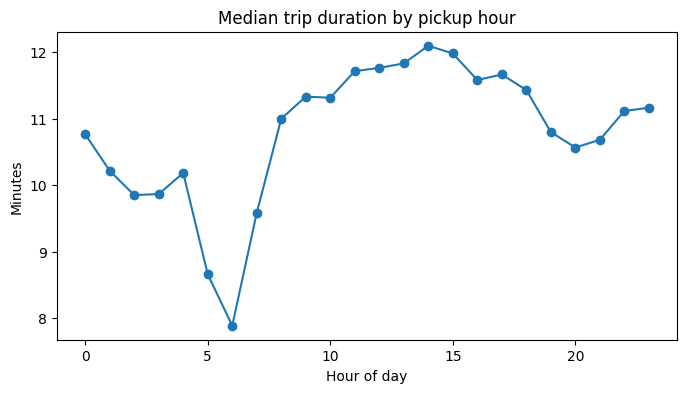

In [6]:
# Fig 5: median duration by hour
plt.figure(figsize=(8, 4))
(df.groupby("hour").trip_duration.median() / 60).plot(marker="o")
plt.title("Median trip duration by pickup hour")
plt.xlabel("Hour of day"); plt.ylabel("Minutes")
plt.savefig("figures/fig5_median_by_hour.png", dpi=200, bbox_inches="tight")

In [7]:
print(len(df), df.trip_duration.max() / 3600)

1453583 3.9563888888888887


In [8]:
by_hour = df.groupby("hour").size()
print(by_hour.idxmin(), by_hour.min(), by_hour.idxmax(), by_hour.max())
med = df.groupby("hour").trip_duration.median() / 60
print(med.idxmin(), med.min(), med.idxmax(), med.max())

5 14898 18 90310
6 7.883333333333334 14 12.1
